In [39]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df=pd.read_csv("loan_data_set.csv")
df.head(5)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [22]:
df.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

In [20]:
# Categorical columns
categorical_cols = [
    "Gender",
    "Married",
    "Dependents",
    "Self_Employed"
]

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])


In [23]:
# Numerical columns
numerical_cols = [
    "LoanAmount",
    "Loan_Amount_Term",
    "Credit_History"
]

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

In [24]:
df.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

In [17]:
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [25]:

# 7. Descriptive Statistics
# ============================================================

print("\nNumerical Descriptive Statistics:")
print(df.describe())

print("\nCategorical Descriptive Statistics:")
print(df.describe(include="object"))


Numerical Descriptive Statistics:
       ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
count       614.000000         614.000000  614.000000        614.000000   
mean       5403.459283        1621.245798  147.350163        341.628664   
std        6109.041673        2926.248369   87.444391         65.656819   
min         150.000000           0.000000    9.000000         12.000000   
25%        2877.500000           0.000000  100.000000        360.000000   
50%        3812.500000        1188.500000  128.000000        360.000000   
75%        5795.000000        2297.250000  167.750000        360.000000   
max       81000.000000       41667.000000  700.000000        480.000000   

       Credit_History  
count      614.000000  
mean         0.835505  
std          0.371027  
min          0.000000  
25%          1.000000  
50%          1.000000  
75%          1.000000  
max          1.000000  

Categorical Descriptive Statistics:
         Loan_ID Gender Married Depe

C:\Users\A\AppData\Local\Temp\ipykernel_3608\2134426800.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.describe(include="object"))


In [19]:
print(df.duplicated().sum())

0


# 8. Loan Approval Summary

In [28]:

# ============================================================

print("\nLoan Status Count:")
print(df["Loan_Status"].value_counts())

print("\nLoan Status Percentage:")
print(
    (df["Loan_Status"].value_counts(normalize=True) * 100).round(2)
)


Loan Status Count:
Loan_Status
Y    422
N    192
Name: count, dtype: int64

Loan Status Percentage:
Loan_Status
Y    68.73
N    31.27
Name: proportion, dtype: float64


1.Loan Approval vs Rejection

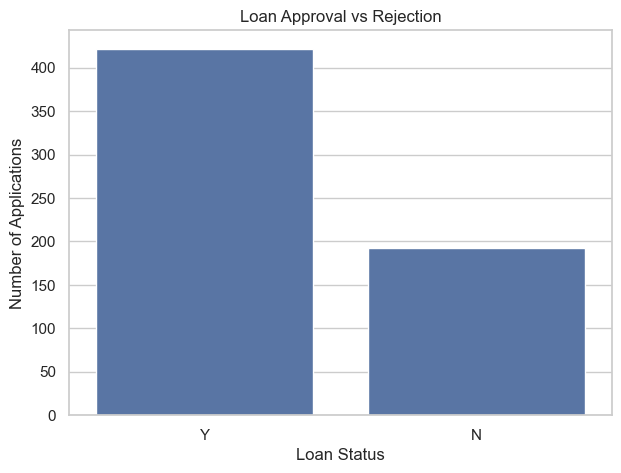

In [29]:


plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Loan_Status"
)

plt.title("Loan Approval vs Rejection")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.show()


2 - Gender Distribution


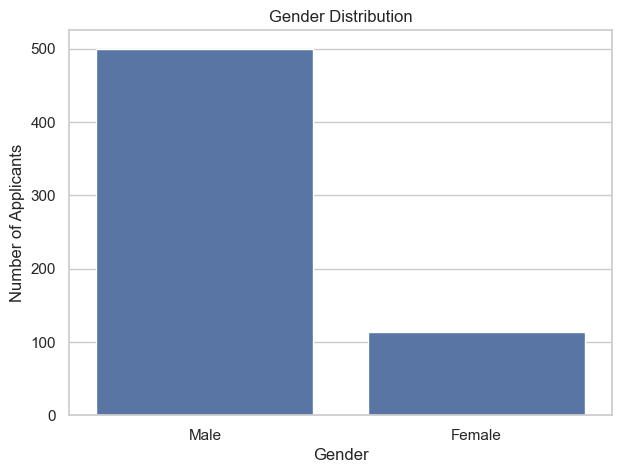

In [30]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Gender"
)

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Applicants")
plt.show()


3 - Education vs Loan Status


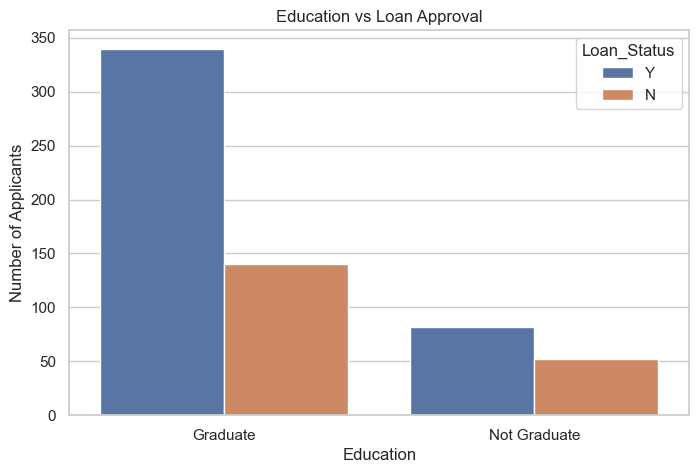

In [31]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Education",
    hue="Loan_Status"
)

plt.title("Education vs Loan Approval")
plt.xlabel("Education")
plt.ylabel("Number of Applicants")
plt.show()


4 - Property Area vs Loan Status


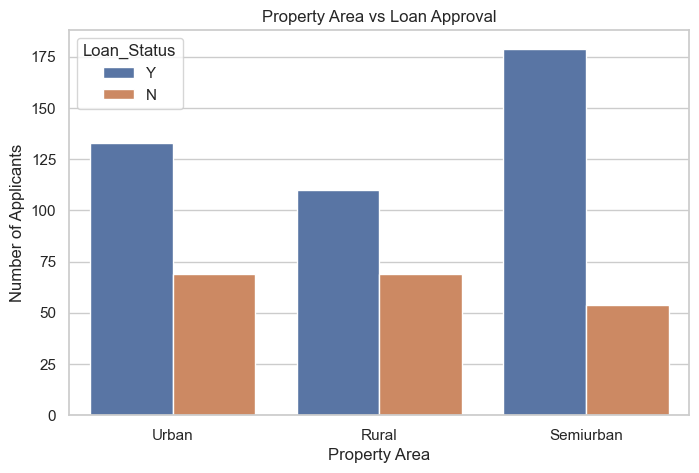

In [32]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Property_Area",
    hue="Loan_Status"
)

plt.title("Property Area vs Loan Approval")
plt.xlabel("Property Area")
plt.ylabel("Number of Applicants")
plt.show()


5 - Credit History vs Loan Status

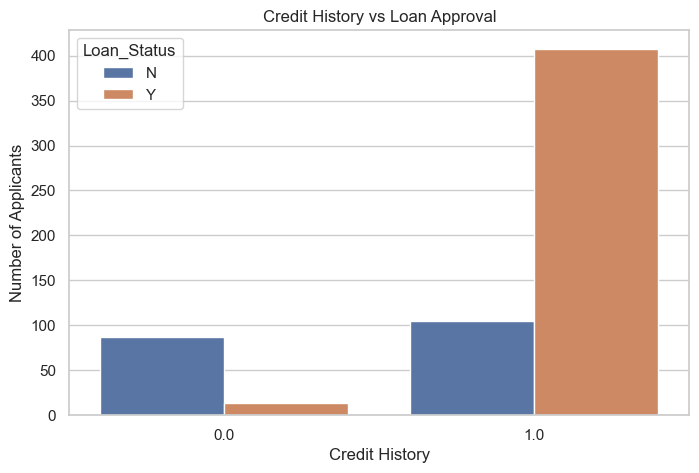

In [33]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Credit_History",
    hue="Loan_Status"
)

plt.title("Credit History vs Loan Approval")
plt.xlabel("Credit History")
plt.ylabel("Number of Applicants")
plt.show()


 6 - Applicant Income Distribution

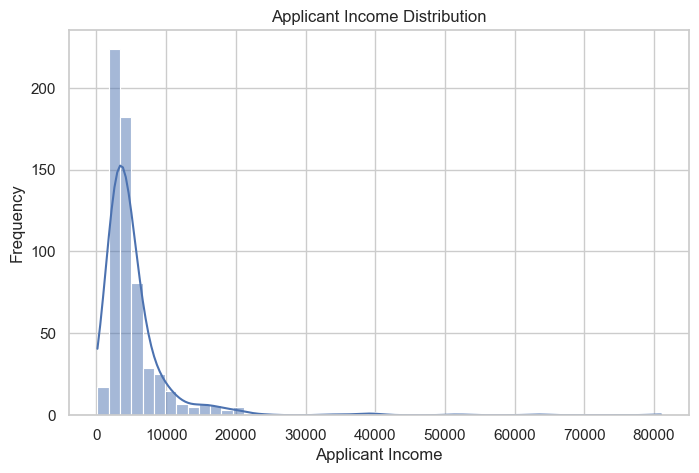

In [34]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="ApplicantIncome",
    kde=True
)

plt.title("Applicant Income Distribution")
plt.xlabel("Applicant Income")
plt.ylabel("Frequency")
plt.show()

7 - Loan Amount Distribution

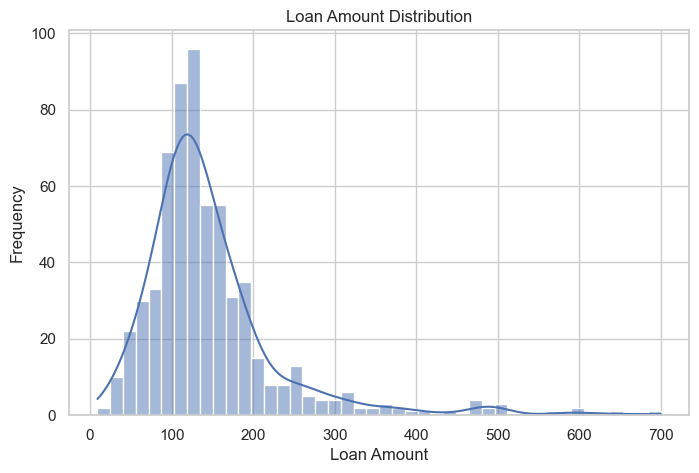

In [35]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="LoanAmount",
    kde=True
)

plt.title("Loan Amount Distribution")
plt.xlabel("Loan Amount")
plt.ylabel("Frequency")
plt.show()


8 - Applicant Income vs Loan Amount


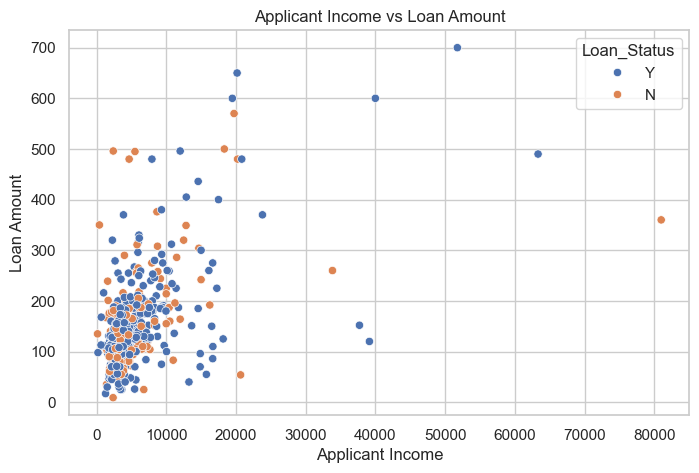

In [36]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="ApplicantIncome",
    y="LoanAmount",
    hue="Loan_Status"
)

plt.title("Applicant Income vs Loan Amount")
plt.xlabel("Applicant Income")
plt.ylabel("Loan Amount")
plt.show()


 9 - Loan Amount by Loan Status


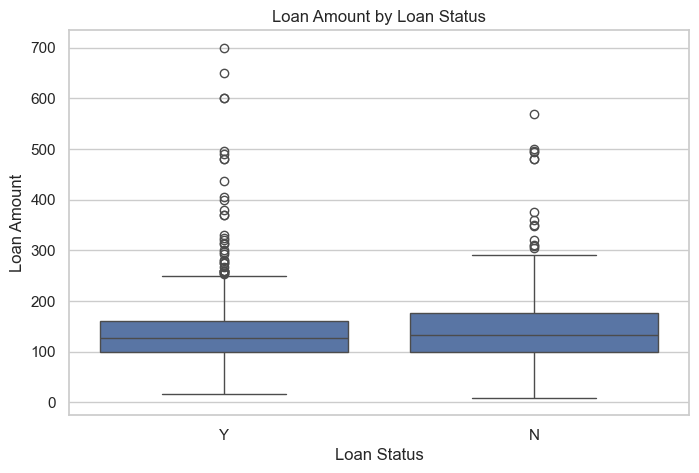

In [37]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Loan_Status",
    y="LoanAmount"
)

plt.title("Loan Amount by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Loan Amount")
plt.show()

10 - Dependents vs Loan Status


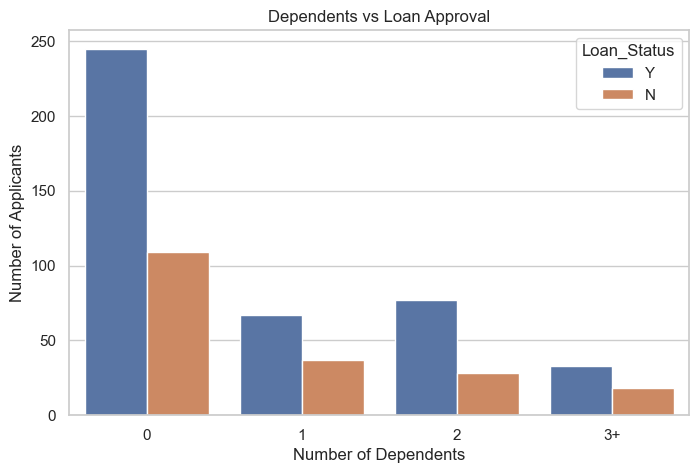

In [38]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Dependents",
    hue="Loan_Status"
)

plt.title("Dependents vs Loan Approval")
plt.xlabel("Number of Dependents")
plt.ylabel("Number of Applicants")
plt.show()


11 - Correlation Heatmap

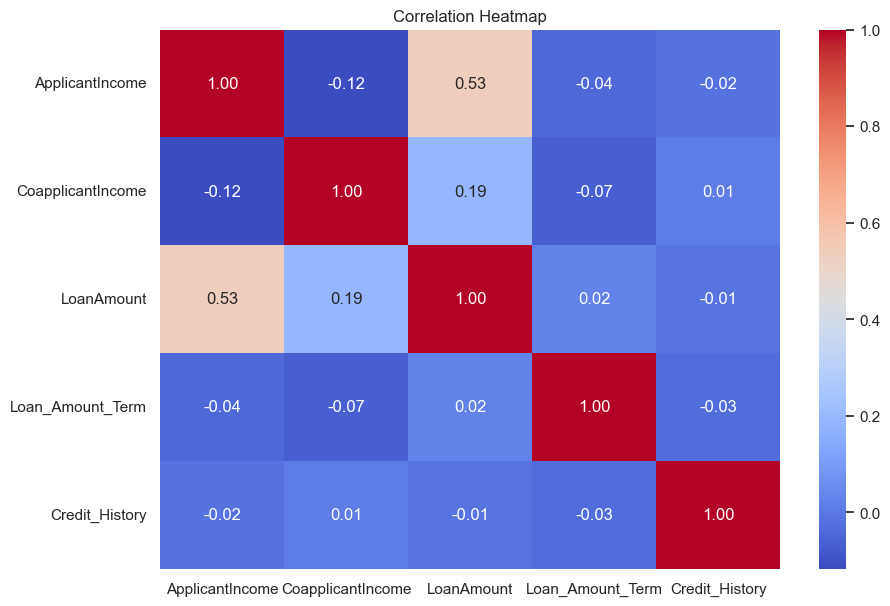

In [40]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

# ============================================================
#   12 - Outlier Analysis
# ============================================================

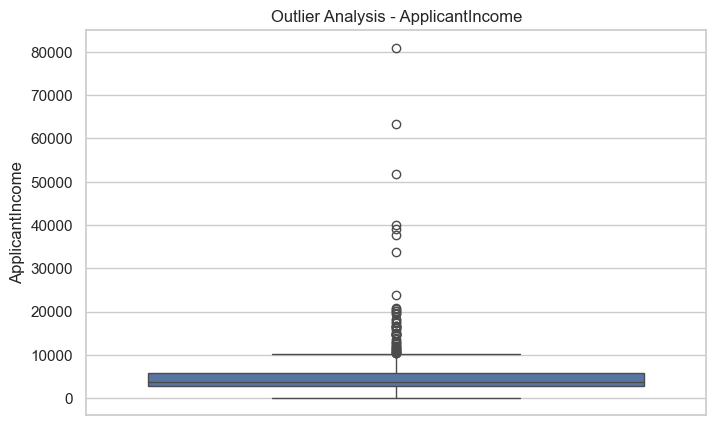

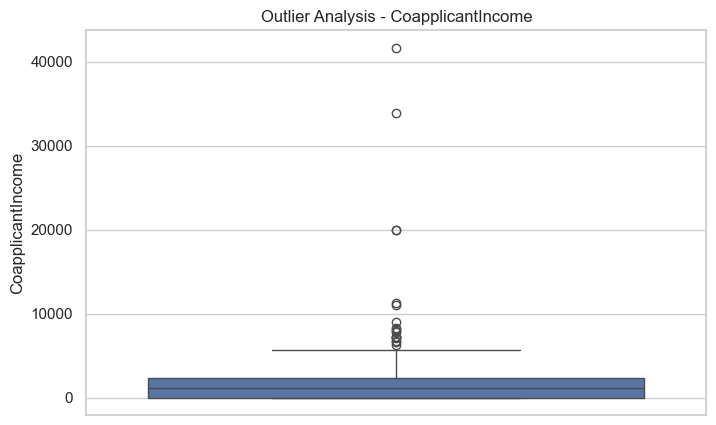

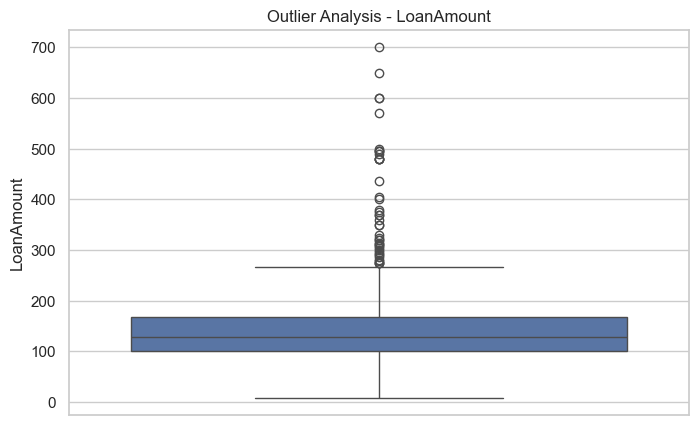

In [41]:


outlier_columns = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount"
]

for col in outlier_columns:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        y=col
    )

    plt.title(f"Outlier Analysis - {col}")
    plt.ylabel(col)

    plt.show()


# ============================================================
# 21. Approval Rate by Credit History
# ============================================================

In [42]:
credit_approval = pd.crosstab(
    df["Credit_History"],
    df["Loan_Status"],
    normalize="index"
) * 100

print("\nLoan Approval Rate by Credit History:")
print(credit_approval.round(2))



Loan Approval Rate by Credit History:
Loan_Status         N      Y
Credit_History              
0.0             86.14  13.86
1.0             20.47  79.53


# ============================================================
# 22. Approval Rate by Property Area
# ============================================================

In [43]:
property_approval = pd.crosstab(
    df["Property_Area"],
    df["Loan_Status"],
    normalize="index"
) * 100

print("\nLoan Approval Rate by Property Area:")
print(property_approval.round(2))


Loan Approval Rate by Property Area:
Loan_Status        N      Y
Property_Area              
Rural          38.55  61.45
Semiurban      23.18  76.82
Urban          34.16  65.84


# ============================================================
# 23. Approval Rate by Education
# ============================================================

In [44]:
education_approval = pd.crosstab(
    df["Education"],
    df["Loan_Status"],
    normalize="index"
) * 100

print("\nLoan Approval Rate by Education:")
print(education_approval.round(2))


Loan Approval Rate by Education:
Loan_Status       N      Y
Education                 
Graduate      29.17  70.83
Not Graduate  38.81  61.19


# ============================================================
# 24. Grouped Business Analysis
# ============================================================

In [45]:

summary = df.groupby("Loan_Status").agg(
    Average_Applicant_Income=("ApplicantIncome", "mean"),
    Average_Coapplicant_Income=("CoapplicantIncome", "mean"),
    Average_Loan_Amount=("LoanAmount", "mean"),
    Average_Loan_Term=("Loan_Amount_Term", "mean")
)

print("\nBusiness Summary:")
print(summary.round(2))


Business Summary:
             Average_Applicant_Income  Average_Coapplicant_Income  \
Loan_Status                                                         
N                             5446.08                     1877.81   
Y                             5384.07                     1504.52   

             Average_Loan_Amount  Average_Loan_Term  
Loan_Status                                          
N                         153.13             344.88  
Y                         144.72             340.15  


# ============================================================
# 25. Save Cleaned Dataset
# ============================================================

In [46]:
df.to_csv(
    "loan_data_cleaned.csv",
    index=False
)

print("\nCleaned dataset saved as:")
print("loan_data_cleaned.csv")


Cleaned dataset saved as:
loan_data_cleaned.csv


# ============================================================
# 26. Final Summary
# ============================================================

In [47]:
print("\n" + "=" * 60)
print("EDA COMPLETED SUCCESSFULLY")
print("=" * 60)

print("Total Records:", len(df))
print("Total Columns:", len(df.columns))

approval_rate = (
    df["Loan_Status"].value_counts(normalize=True).get("Y", 0) * 100
)

print(f"Loan Approval Rate: {approval_rate:.2f}%")

print("\nTop Numerical Statistics:")
print(
    df[
        [
            "ApplicantIncome",
            "CoapplicantIncome",
            "LoanAmount"
        ]
    ].describe().round(2)
)


EDA COMPLETED SUCCESSFULLY
Total Records: 614
Total Columns: 13
Loan Approval Rate: 68.73%

Top Numerical Statistics:
       ApplicantIncome  CoapplicantIncome  LoanAmount
count           614.00             614.00      614.00
mean           5403.46            1621.25      147.35
std            6109.04            2926.25       87.44
min             150.00               0.00        9.00
25%            2877.50               0.00      100.00
50%            3812.50            1188.50      128.00
75%            5795.00            2297.25      167.75
max           81000.00           41667.00      700.00
